In [34]:
import pandas as pd 
import numpy as np 
from sklearn.preprocessing import  LabelEncoder ,  StandardScaler
from sklearn.model_selection  import train_test_split
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.metrics import accuracy_score 


In [35]:
data = {
    'Study_Hours': [2, 3, 5, 7, 8, 1, 4, 6, 9, 2,
                    5, 8, 3, 7, 6, 1, 9, 4, 8, 5],
    'Attendance': [40, 50, 60, 80, 90, 30, 55, 75, 95, 45,
                   65, 85, 50, 90, 70, 35, 95, 60, 88, 72],
    'Assignment': [30, 40, 55, 75, 85, 25, 50, 70, 95, 35,
                   60, 80, 45, 90, 65, 20, 95, 55, 85, 70],
    'Result': ['Fail', 'Fail', 'Fail', 'Pass', 'Pass',
               'Fail', 'Fail', 'Pass', 'Pass', 'Fail',
               'Pass', 'Pass', 'Fail', 'Pass', 'Pass',
               'Fail', 'Pass', 'Fail', 'Pass', 'Pass']
}

df = pd.DataFrame(data)
print(df.head())

   Study_Hours  Attendance  Assignment Result
0            2          40          30   Fail
1            3          50          40   Fail
2            5          60          55   Fail
3            7          80          75   Pass
4            8          90          85   Pass


In [36]:
# feature engineering 

In [37]:
for col in df.columns:
    print(f"col : {col}  ||  dtype :  {df[col].dtype}   || missing : {df[col].isna().sum()}")

col : Study_Hours  ||  dtype :  int64   || missing : 0
col : Attendance  ||  dtype :  int64   || missing : 0
col : Assignment  ||  dtype :  int64   || missing : 0
col : Result  ||  dtype :  object   || missing : 0


In [38]:
num_cols = []
cat_cols = [] 

for col in df.columns:
    if pd.api.types.is_numeric_dtype(df[col]):
        df[col] =  df[col].fillna(df[col].mean())
    else:
        df[col] = df[col].fillna(df[col].mode()[0])

In [39]:
df['Attendance'] =  np.log1p(df['Attendance'])

In [40]:
X = df.drop(columns=['Result'],axis =1)
y = df['Result']

In [41]:
x_train,x_test,y_train,y_test =  train_test_split(X,y,test_size= 0.2)

In [42]:
from sklearn.preprocessing  import StandardScaler 
scaler =  StandardScaler()
le =  LabelEncoder()

In [43]:

for col in num_cols :
    x_train[num_cols] = scaler.fit_transform(x_train[num_cols])
    x_test[num_cols] =  scaler.transform(x_test[num_cols])

for col in cat_cols :
    x_train[cat_cols] = le.fit_transform(x_train)
    x_test[cat_cols] = le.transform(x_test)
    


In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X = pca.fit_transform(df[['Study_Hours', 'Attendance', 'Assignment']])
y = df['Result']

In [45]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 1.0


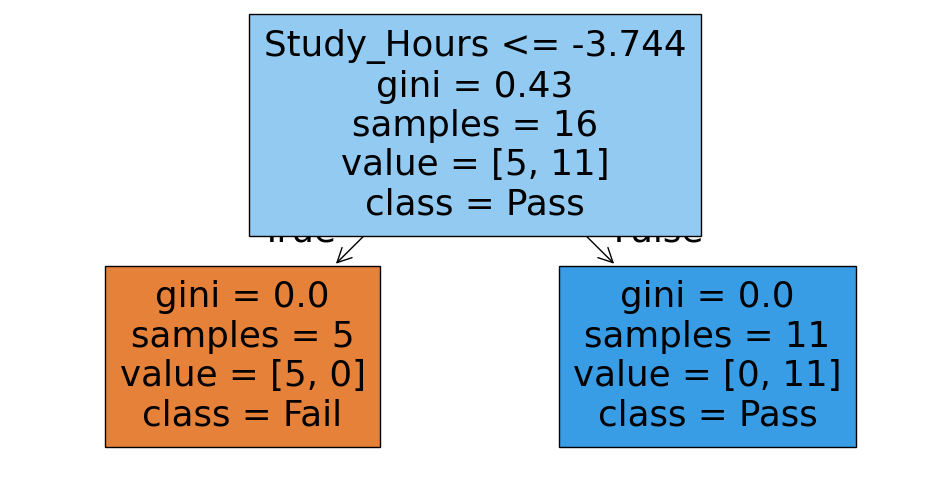

In [47]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plot_tree(model, feature_names=x_train.columns,
          class_names=['Fail', 'Pass'],
          filled=True)

plt.show()